# Analysis: weekly covered calls on bitcoin

The decision: a holder of bitcoin writes weekly calls and must pick the strike and the fraction of the stack to write. The held-out score, in the units of the decision (growth of the stack in BTC per coin held, against holding without selling), is computed in this notebook. `PROPOSAL.md` has the hypothesis, `decisions.md` has the history of each choice below, and issue 2 on the repository has the instructor's feedback that shaped the strike and the sizing rule.

**The score is a calculation, not a Deribit fill.** Every premium below is a Black-Scholes price at the previous day's DVOL. DVOL is also an input to the forecast, so the premium and the predictor share one source. Real option quotes would be needed to remove that.

## Setup

Packages are pinned in `requirements.txt` for the interpreter in `.python-version`. The only random draws are the bootstrap resamples of the training windows, seeded with `SEED` (recorded in `decisions.md`). The predictive distributions and the sizing rule below are deterministic.

In [1]:
import hashlib
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import minimize
from scipy.stats import binomtest, norm

SEED = 600
rng = np.random.default_rng(SEED)
DATA, FIG = Path("data"), Path("fig")
FIG.mkdir(exist_ok=True)

## Question

Does trailing realized volatility, added to Deribit's implied-volatility index (DVOL), give a better predictive distribution for bitcoin's next-week return than DVOL alone, so that the strike and the fraction of the stack written to weekly calls earn more growth, in BTC per coin held, than holding or writing a full call every week?

The quantity is the distribution of the 7-day log return of BTC/USD, from one Friday 08:00 UTC option expiry to the next, in log points (0.05 is about 5 percent). The decision has two parts: the strike $K = S_0 e^{q}$ of a call sold at $S_0$, and the fraction $f \in [0, 1]$ of the stack written. The loss and the rule are defined below.

The layers from data to decision are drawn below and saved as `fig/layers.png`.

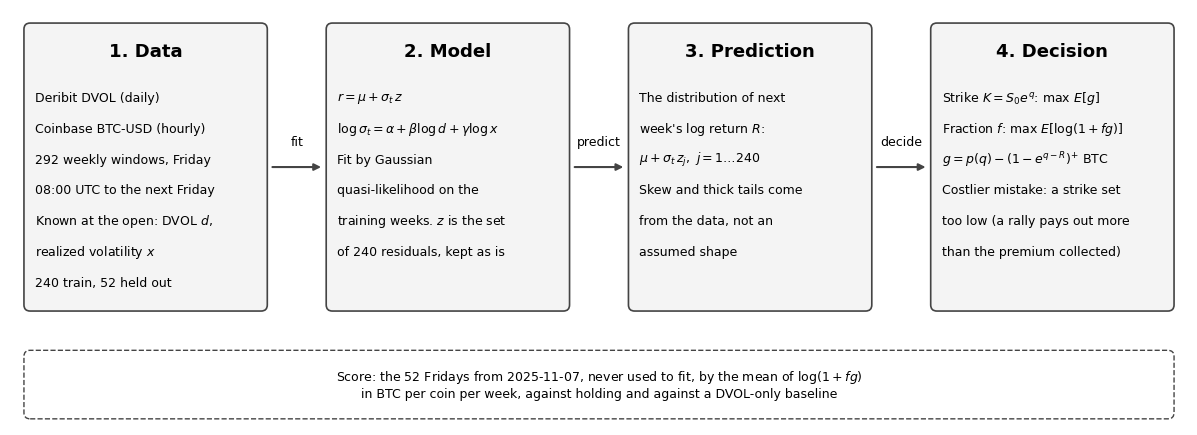

In [2]:
from matplotlib.patches import FancyBboxPatch

layers = [
    ("1. Data", [
        "Deribit DVOL (daily)",
        "Coinbase BTC-USD (hourly)",
        "292 weekly windows, Friday",
        "08:00 UTC to the next Friday",
        "Known at the open: DVOL $d$,",
        "realized volatility $x$",
        "240 train, 52 held out"]),
    ("2. Model", [
        r"$r = \mu + \sigma_t\, z$",
        r"$\log\sigma_t = \alpha + \beta\log d + \gamma\log x$",
        "Fit by Gaussian",
        "quasi-likelihood on the",
        "training weeks. $z$ is the set",
        "of 240 residuals, kept as is"]),
    ("3. Prediction", [
        "The distribution of next",
        "week's log return $R$:",
        r"$\mu + \sigma_t\, z_j,\ j = 1 \ldots 240$",
        "Skew and thick tails come",
        "from the data, not an",
        "assumed shape"]),
    ("4. Decision", [
        r"Strike $K = S_0 e^{q}$: max $E[g]$",
        r"Fraction $f$: max $E[\log(1 + f g)]$",
        r"$g = p(q) - (1 - e^{q-R})^{+}$ BTC",
        "Costlier mistake: a strike set",
        "too low (a rally pays out more",
        "than the premium collected)"]),
]
arrows = ["fit", "predict", "decide"]

fig, ax = plt.subplots(figsize=(15.2, 5.4))
ax.set_xlim(0, 15.2); ax.set_ylim(0, 5.4); ax.axis("off")
bw, gap, x0, top, bh = 3.1, 0.8, 0.2, 5.2, 3.7
for i, (title, body) in enumerate(layers):
    x = x0 + i * (bw + gap)
    ax.add_patch(FancyBboxPatch((x, top - bh), bw, bh, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc="#f4f4f4", ec="#444444", lw=1.2))
    ax.text(x + bw / 2, top - 0.35, title, ha="center", va="center", fontsize=13, fontweight="bold")
    for j, line in enumerate(body):
        ax.text(x + 0.12, top - 0.95 - 0.4 * j, line, ha="left", va="center", fontsize=9)
    if i < 3:
        ax.annotate("", xy=(x + bw + gap - 0.05, top - bh / 2), xytext=(x + bw + 0.05, top - bh / 2),
                    arrowprops=dict(arrowstyle="-|>", lw=1.5, color="#444444"))
        ax.text(x + bw + gap / 2, top - bh / 2 + 0.25, arrows[i], ha="center", va="bottom", fontsize=9)
ax.add_patch(FancyBboxPatch((x0, 0.1), 4 * bw + 3 * gap, 0.85, boxstyle="round,pad=0.02,rounding_size=0.08",
                            fc="white", ec="#444444", lw=1.0, ls="--"))
ax.text(x0 + (4 * bw + 3 * gap) / 2, 0.525,
        "Score: the 52 Fridays from 2025-11-07, never used to fit, by the mean of $\\log(1 + f g)$\n"
        "in BTC per coin per week, against holding and against a DVOL-only baseline",
        ha="center", va="center", fontsize=9)
fig.savefig(FIG / "layers.png", dpi=150, bbox_inches="tight")
plt.show()

## Data

Two files, downloaded from their sources by `scripts/fetch_covered_call.py` (commands, sources and hashes are in `data/README.md`): Deribit's DVOL index (daily) and Coinbase BTC-USD hourly candles. The cell below checks each file against the SHA-256 in `data/README.md` before anything is read.

In [3]:
expected = {}
for line in (DATA / "README.md").read_text().splitlines():
    m = re.match(r"\| `(\w+\.csv)` .*`([0-9a-f]{64})` \|$", line)
    if m:
        expected[m[1]] = m[2]

for name in ["dvol_daily.csv", "btcusd_hourly.csv"]:
    got = hashlib.sha256((DATA / name).read_bytes()).hexdigest()
    assert got == expected[name], f"{name}: hash {got} does not match data/README.md"
print("hashes match:", sorted(expected))

px = pd.read_csv(DATA / "btcusd_hourly.csv", parse_dates=["time_utc"]).set_index("time_utc")
dvol = pd.read_csv(DATA / "dvol_daily.csv", parse_dates=["date"]).set_index("date")

# Price at the start of each hour (the candle's open). The 13 hours with no trades
# are forward-filled, which gives them a zero return.
p = px["open"].reindex(pd.date_range(px.index[0], px.index[-1], freq="h")).ffill()
print(f"{len(px)} hourly rows, {len(p) - len(px)} filled; {len(dvol)} DVOL days")

hashes match: ['btcusd_hourly.csv', 'dvol_daily.csv']
49931 hourly rows, 13 filled; 2058 DVOL days


### Weekly windows

One row per Friday 08:00 UTC ($t_0$) to the next Friday 08:00 UTC ($T$). Everything used as an input is known at $t_0$:

- `dvol`: the close of the previous UTC day's DVOL (a 30-day annualized implied volatility), so the day that contains $t_0$ is never used.
- `rv7`, `rv30`: annualized realized volatility, the root mean square of hourly log returns over the 7 and 30 days ending at $t_0$.

`d`, `x7` and `x30` rescale those three annualized numbers to a one-week horizon by $\sqrt{7/365}$, so they are comparable to the weekly return `r = log(S_T / S_0)`.

In [4]:
lr2 = np.log(p).diff() ** 2
rv7 = np.sqrt(lr2.rolling(7 * 24).mean() * 8760)
rv30 = np.sqrt(lr2.rolling(30 * 24).mean() * 8760)

rows = []
for t0 in p.index[(p.index.weekday == 4) & (p.index.hour == 8)]:
    T = t0 + pd.Timedelta(days=7)
    prev_day = t0.normalize() - pd.Timedelta(days=1)
    if T > p.index[-1] or prev_day not in dvol.index or np.isnan(rv30[t0]):
        continue
    rows.append(dict(t0=t0, T=T, S0=p[t0], ST=p[T], dvol=dvol.close[prev_day] / 100,
                     rv7=rv7[t0], rv30=rv30[t0]))
w = pd.DataFrame(rows)
w["r"] = np.log(w.ST / w.S0)
wk = np.sqrt(7 / 365)
w["d"], w["x7"], w["x30"] = w.dvol * wk, w.rv7 * wk, w.rv30 * wk
print(f"{len(w)} windows, {w.t0.iloc[0]:%Y-%m-%d} to {w.t0.iloc[-1]:%Y-%m-%d} (last window ends {w['T'].iloc[-1]:%Y-%m-%d})")

292 windows, 2021-04-02 to 2026-10-30 (last window ends 2026-11-06)


### Raw data

One plot of the raw series and one table of summary statistics, before any model.

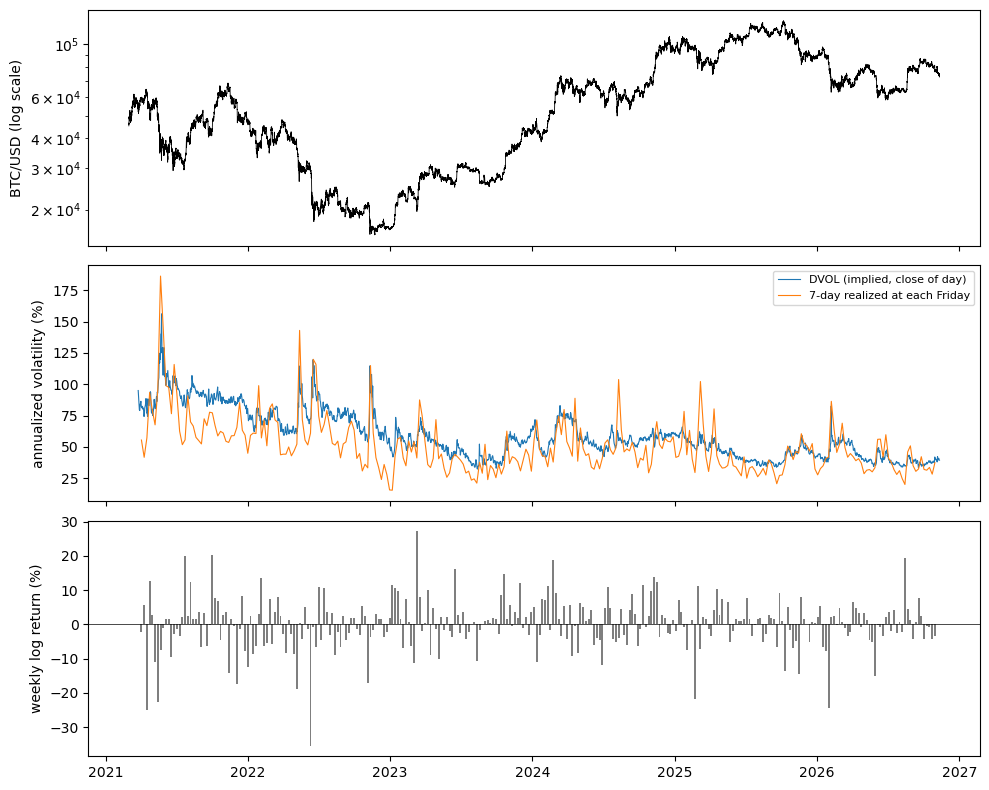

In [5]:
fig, ax = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
ax[0].plot(p.index, p.values, lw=0.6, color="black")
ax[0].set_yscale("log")
ax[0].set_ylabel("BTC/USD (log scale)")
ax[1].plot(dvol.index + pd.Timedelta(days=1), dvol.close, lw=0.8, label="DVOL (implied, close of day)")
ax[1].plot(w.t0, w.rv7 * 100, lw=0.8, label="7-day realized at each Friday")
ax[1].set_ylabel("annualized volatility (%)")
ax[1].legend(loc="upper right", fontsize=8)
ax[2].bar(w.t0, w.r * 100, width=5, color="tab:gray")
ax[2].axhline(0, color="black", lw=0.5)
ax[2].set_ylabel("weekly log return (%)")
fig.tight_layout()
fig.savefig(FIG / "raw_covered_call.png", dpi=150)
plt.show()

In [6]:
summary = w[["r", "dvol", "rv7", "rv30"]].describe(percentiles=[0.1, 0.5, 0.9]).T
summary = summary.rename(columns={"count": "n", "10%": "p10", "50%": "median", "90%": "p90"})
display(summary[["n", "mean", "std", "min", "p10", "median", "p90", "max"]].round(3))

,n,mean,std,min,p10,median,p90,max
r,292.0,0.001,0.074,-0.354,-0.075,0.007,0.082,0.271
dvol,292.0,0.592,0.186,0.336,0.385,0.550,0.873,1.198
rv7,292.0,0.506,0.219,0.155,0.294,0.455,0.763,1.864
rv30,292.0,0.527,0.182,0.254,0.327,0.502,0.722,1.368


### Measurement versus the quantity the decision needs

The decision needs the price a 7-day Deribit call would fetch on Friday at 08:00 UTC and the bitcoin price at its expiry. The data measure something close to each, and each gap is either bias (it pushes the same way every week) or noise (it moves a number up or down at random and averages out).

- **Implied volatility.** DVOL is a 30-day implied volatility and the options are 7-day, so it is not the volatility the premium prices. The gap is mostly bias, not noise: implied volatility was above the volatility that arrived in 81 percent of training weeks and 75 percent of held-out weeks, and the size of the gap changed between them (see the implied versus realized check below). The fitted $\alpha$ and $\beta < 1$ absorb a constant part of it, but not the change.
- **Premium.** A Black-Scholes price at DVOL has no skew, no bid-ask spread and no fee. That is bias against the seller, who is paid the bid and not the model price, so every gain here is overstated by an amount I cannot measure. The premium check below bounds it: the gain is gone near a 53 percent haircut.
- **Prices.** The price of a week is the open of the Coinbase hourly candle at Friday 08:00 UTC, while Deribit settles on its own index. That difference should be noise, since neither venue is systematically higher, but I did not measure it. Hours with no trades (13 of 49,931) are forward-filled.
- **Realized volatility.** Computed from hourly returns, it is a noisy measure of a week's volatility. Noise in an input can pull its coefficient toward zero, which is one more reason $\gamma$ is hard to find.

## Split

The decision is about a later time, so the last year is held out: the last 52 weekly windows, the Fridays from the cutoff below onward. Nothing is fit, scaled, or chosen on those rows. Training windows all end on or before the cutoff. The cutoff is recorded in `decisions.md`.

In [7]:
N_HOLD = 52
train, test = w.iloc[:-N_HOLD].copy(), w.iloc[-N_HOLD:].copy()
CUTOFF = test.t0.iloc[0]
assert train["T"].max() <= CUTOFF and train.t0.max() < CUTOFF
print(f"train {len(train)} windows ({train.t0.iloc[0]:%Y-%m-%d} to {train.t0.iloc[-1]:%Y-%m-%d}); "
      f"held out {len(test)} windows (from {CUTOFF:%Y-%m-%d} to {test.t0.iloc[-1]:%Y-%m-%d})")
display(pd.concat({"train": train[["r", "dvol", "rv7", "rv30"]].agg(["mean", "std"]),
                   "held out": test[["r", "dvol", "rv7", "rv30"]].agg(["mean", "std"])}).round(3))

train 240 windows (2021-04-02 to 2025-10-31); held out 52 windows (from 2025-11-07 to 2026-10-30)


r   dvol    rv7   rv30
train    mean  0.002  0.626  0.526  0.548
         std   0.076  0.185  0.230  0.190
held out mean -0.006  0.438  0.416  0.431
         std   0.064  0.082  0.125  0.094

## Decision rule and loss

**Premium and payout.** For one coin of cover, a call struck at $K = S_0 e^{q}$ pays out $\max(S_T - K, 0)/S_T = (1 - e^{q - R})^+$ in BTC, where $R = \log(S_T/S_0)$. The premium is the Black-Scholes call price at zero rate, with $\sigma$ the previous day's DVOL and $T = 7/365$, divided by $S_0$ to give BTC: $p(q)$. The BTC gained from writing one call against one coin is

$$g(q, R) = p(q) - (1 - e^{q - R})^+ .$$

**Strike: the critical fractile.** Given a predictive distribution for $R$, the strike maximizes the expected gain $E[g(q, R)]$. Setting the derivative to zero, with $p'(q) = -e^{q} N(d_2)$, gives

$$N(d_2(q)) = E\left[\frac{S_0}{S_T}\,\mathbf 1\{S_T > K\}\right].$$

The right side is the forecast chance of finishing above the strike, weighted by the payout's $S_0/S_T$. The left side is the chance the premium's slope implies. The strike is where they are equal. A strike set too low costs more, since a rally pays out more than the premium collects, and that cost is what picks the number: no fixed fractile such as 0.9 appears. The strike is searched on a grid from at the money ($q = 0$) to 30 percent above, in steps of 0.005.

**Fraction written: Kelly.** After the strike is chosen, writing a fraction $f$ of the stack gives wealth per coin $W = 1 + f\,g$ next week. The fraction maximizes the average of $\log W$ over draws of $R$ from the predictive distribution, over $f \in [0, 1]$ in steps of 0.01. Zero is holding and one is a fully covered call. The win-or-lose Kelly formula does not apply, since the loss is continuous and occurs only above the strike. The edge is estimated and full Kelly overbets when it is noisy, so half of that fraction is reported too.

**Score.** The growth of the week is $\log W$ with the realized return, and the score is its mean over the held-out Fridays, against holding ($f = 0$, growth 0) and against writing a full call every week ($f = 1$). The rule is frozen on the training windows. Consecutive Friday-to-Friday returns do not overlap, so the 52 held-out Fridays are scored one by one. Their forecast inputs do overlap (DVOL and realized volatility move slowly), so the standard errors treat weeks as independent and are probably a little too small.

In [8]:
T_WEEK = 7 / 365
Q = np.arange(0, 0.3001, 0.005)   # strike grid: K = S0 * exp(q)
F = np.linspace(0, 1, 101)        # fraction of the stack written


def premium(dvol):
    """Black-Scholes call price in BTC per coin (S0 = 1, zero rate), for each strike in Q."""
    s = (np.asarray(dvol) * np.sqrt(T_WEEK))[:, None]
    d1 = (-Q[None, :] + 0.5 * s**2) / s
    return norm.cdf(d1) - np.exp(Q)[None, :] * norm.cdf(d1 - s)


def plan(dvol, R):
    """Strike and fraction from draws R (weeks x draws) of the 7-day log return."""
    prem = premium(dvol)
    payout = np.maximum(0, 1 - np.exp(Q[None, :, None] - R[:, None, :])).mean(axis=2)
    exp_gain = prem - payout
    i = exp_gain.argmax(axis=1)
    q, rows = Q[i], np.arange(len(i))
    pr = prem[rows, i]
    g = pr[:, None] - np.maximum(0, 1 - np.exp(q[:, None] - R))
    log_growth = np.log1p(F[None, :, None] * g[:, None, :]).mean(axis=2)
    s = np.asarray(dvol) * np.sqrt(T_WEEK)
    return pd.DataFrame({
        "q": q, "f": F[log_growth.argmax(axis=1)], "prem": pr, "exp_gain": exp_gain[rows, i],
        "p_exceed": (R > q[:, None]).mean(axis=1),
        "p_weighted": (np.exp(-R) * (R > q[:, None])).mean(axis=1),
        "p_premium": norm.cdf((-q - 0.5 * s**2) / s),
    })


def growth(df, pl, f):
    """Realized log growth of the stack for fraction f, and the gain g, in each week."""
    g = pl.prem.values - np.maximum(0, 1 - np.exp(pl.q.values - df.r.values))
    return np.log1p(f * g), g

## Baseline: DVOL alone

If next week's log return were normal with zero mean and the volatility DVOL says, $R \sim N(0,\ \mathrm{DVOL}^2 \cdot 7/365)$. The baseline applies the same rule to that distribution, represented by 2,000 equally spaced quantiles.

The premium is priced at the same DVOL, so under the baseline's own distribution the premium is close to fair, and the strike is chosen where the small remaining edge is largest.

In [9]:
M_BASE = 2000
R_base = norm.ppf((np.arange(M_BASE) + 0.5) / M_BASE)[None, :] * test.d.values[:, None]
pl_base = plan(test.dvol.values, R_base)
print(f"baseline plan, held out: mean strike {100 * (np.exp(pl_base.q) - 1).mean():.1f}% out of the money, "
      f"mean fraction {pl_base.f.mean():.2f}; strikes at the at-the-money edge of the grid in {(pl_base.q == 0).mean():.0%} of weeks")

baseline plan, held out: mean strike 0.0% out of the money, mean fraction 0.76; strikes at the at-the-money edge of the grid in 100% of weeks


## Model: location-scale model with empirical shape

$$r_t = \mu + \sigma_t\,z_t, \qquad \log \sigma_t = \alpha + \beta \log d_t + \gamma \log x_t,$$

where $d_t$ is DVOL and $x_t$ is realized volatility, both scaled to one week. The parameters $(\mu, \alpha, \beta, \gamma)$ are fit by Gaussian quasi-likelihood on the training windows (`scipy.optimize.minimize`). The standardized residuals $z_t = (r_t - \hat\mu)/\hat\sigma_t$ are kept as they are: the predictive distribution for a new Friday is $\hat\mu + \hat\sigma_t z_j$ over the training residuals $z_j$, which carries the skew and the thick tails of the data instead of assuming a normal shape.

- $\mu$: the typical weekly log return (bitcoin's drift).
- $\alpha$: the base level of weekly volatility when both inputs are one.
- $\beta$: how much of DVOL's movement passes into next week's volatility. The baseline is $\alpha = 0$, $\beta = 1$, $\gamma = 0$, $\mu = 0$ with a normal shape.
- $\gamma$: what trailing realized volatility adds once DVOL is known. The hypothesis is that $\gamma \neq 0$ helps.

The realized-volatility window, 7 or 30 days, is chosen on training windows only: for each of the last 52 training weeks, fit on all earlier training weeks and score that week by the Gaussian log score. The assumption trusted least is the Black-Scholes premium (30-day DVOL for 7-day options, no skew or spread). After it, the shape of $z$ is assumed stable over time and independent of the inputs, estimated from 240 windows.

**Uncertainty.** Every forecast is a predictive distribution, and calibration is checked below on the held-out weeks. Pairs bootstrap of the training windows (300 draws, seed `SEED`) gives intervals for the parameters.

In [10]:
def sigma_of(th, df, x):
    return np.exp(th[1] + th[2] * np.log(df.d) + th[3] * np.log(df[x]))


def nll(th, df, x):
    s = sigma_of(th, df, x)
    return np.sum(np.log(s) + (df.r - th[0]) ** 2 / (2 * s**2))


def fit_scale(df, x):
    th0 = np.array([df.r.mean(), 0.0, 1.0, 0.0])   # start at the baseline
    return minimize(nll, th0, args=(df, x), method="BFGS").x


# choose the realized-volatility window on training windows only
cv = {}
for x in ["x7", "x30"]:
    score = []
    for i in range(len(train) - 52, len(train)):
        past, nxt = train.iloc[:i], train.iloc[[i]]
        th = fit_scale(past, x)
        s = sigma_of(th, nxt, x).values[0]
        score.append(np.log(s) + (nxt.r.values[0] - th[0]) ** 2 / (2 * s**2))
    cv[x] = np.mean(score)
last = train.iloc[-52:]
cv["baseline (DVOL alone)"] = np.mean(np.log(last.d) + last.r**2 / (2 * last.d**2))
print("training-only Gaussian negative log score, last 52 training weeks (lower is better):",
      {k: round(v, 4) for k, v in cv.items()})
X_RV = min(["x7", "x30"], key=cv.get)
print("realized-volatility window chosen:", X_RV)

theta = fit_scale(train, X_RV)
z = ((train.r - theta[0]) / sigma_of(theta, train, X_RV)).values
print(f"fit: mu = {theta[0]:+.4f}, alpha = {theta[1]:+.3f}, beta = {theta[2]:+.3f}, gamma = {theta[3]:+.3f}")
print(f"standardized residuals: mean {z.mean():+.3f}, sd {z.std():.3f}, skew {pd.Series(z).skew():+.2f}, 90th percentile {np.quantile(z, 0.9):.2f} (normal: 1.28)")

training-only Gaussian negative log score, last 52 training weeks (lower is better): {'x7': -2.2806, 'x30': -2.2721, 'baseline (DVOL alone)': -2.2919}
realized-volatility window chosen: x7
fit: mu = +0.0038, alpha = -1.598, beta = +0.633, gamma = -0.213
standardized residuals: mean -0.011, sd 1.000, skew -0.30, 90th percentile 1.21 (normal: 1.28)


In [11]:
NB = 300
boot = np.empty((NB, 4))
for i in range(NB):
    boot[i] = fit_scale(train.iloc[rng.integers(0, len(train), len(train))], X_RV)
coef = pd.DataFrame({"estimate": theta, "boot SE": boot.std(0),
                     "5%": np.percentile(boot, 5, 0), "95%": np.percentile(boot, 95, 0)},
                    index=["mu", "alpha", "beta (on DVOL)", "gamma (on realized vol)"])
display(coef.round(4))

,estimate,boot SE,5%,95%
mu,0.0038,0.0048,-0.0035,0.0120
alpha,-1.5983,0.5938,-2.4842,-0.6032
beta (on DVOL),0.6334,0.3018,0.2035,1.1768
gamma (on realized vol),-0.2130,0.2282,-0.5763,0.1707


In [12]:
sig_te = sigma_of(theta, test, X_RV).values
R_model = theta[0] + sig_te[:, None] * z[None, :]
pl_model = plan(test.dvol.values, R_model)
near = pl_model.q < 0.05
print(f"model plan, held out: strike within 5% of the money in {near.mean():.0%} of weeks (mean fraction there {pl_model.f[near].mean():.2f}), "
      f"and {100 * (np.exp(pl_model.q[~near].min()) - 1):.0f} to {100 * (np.exp(pl_model.q.max()) - 1):.0f}% above spot in the other weeks "
      f"(mean fraction {pl_model.f[~near].mean():.2f}); overall mean fraction {pl_model.f.mean():.2f}")
dv, nr = test.dvol.values, near.values
print(f"DVOL in the near-the-money weeks: {dv[nr].min():.2f} to {dv[nr].max():.2f}; in the others: {dv[~nr].min():.2f} to {dv[~nr].max():.2f}")

model plan, held out: strike within 5% of the money in 56% of weeks (mean fraction there 0.87), and 23 to 29% above spot in the other weeks (mean fraction 1.00); overall mean fraction 0.93
DVOL in the near-the-money weeks: 0.39 to 0.83; in the others: 0.34 to 0.43


## Scores on the held-out year

The rule is frozen: parameters, window and residuals come from the training windows only. Growth is $\log W$ per week, in BTC per coin held, so 0.001 a week is about 5 percent over 52 weeks. All premiums are Black-Scholes at DVOL.

In [13]:
N = len(test)
ones, zeros = np.ones(N), np.zeros(N)
# a naive comparator: a fixed strike about 10% out of the money (grid point 9.5%), set before looking at results
i10 = np.argmin(np.abs(Q - 0.095))
pl_fixed = pd.DataFrame({"q": np.full(N, Q[i10]), "prem": premium(test.dvol.values)[:, i10]})
strategies = {
    "Hold (do not sell)":              (None, zeros),
    "Full call, model strike":         (pl_model, ones),
    "Model, Kelly fraction":           (pl_model, pl_model.f.values),
    "Model, half Kelly":               (pl_model, pl_model.f.values / 2),
    "Full call, fixed 10% strike":     (pl_fixed, ones),
    "Full call, DVOL strike":          (pl_base, ones),
    "DVOL baseline, Kelly fraction":   (pl_base, pl_base.f.values),
    "DVOL baseline, half Kelly":       (pl_base, pl_base.f.values / 2),
}
lg, rows = {}, {}
for name, (pl, f) in strategies.items():
    lg[name] = np.zeros(N) if pl is None else growth(test, pl, f)[0]
    rows[name] = {
        "mean fraction": f.mean(),
        "weeks within 5% of the money": np.nan if pl is None else np.mean(pl.q < 0.05),
        "mean strike, % above spot": np.nan if pl is None else 100 * (np.exp(pl.q) - 1).mean(),
        "growth per week": lg[name].mean(),
        "SE": lg[name].std(ddof=1) / np.sqrt(N),
        "total, 52 weeks": lg[name].sum(),
        "worst week": lg[name].min(),
    }
scores = pd.DataFrame(rows).T
display(scores.round(5))

pairs = [("Model Kelly - Hold", "Model, Kelly fraction", "Hold (do not sell)"),
         ("Model half Kelly - Hold", "Model, half Kelly", "Hold (do not sell)"),
         ("Model Kelly - full call, model strike", "Model, Kelly fraction", "Full call, model strike"),
         ("Model Kelly - DVOL baseline Kelly", "Model, Kelly fraction", "DVOL baseline, Kelly fraction"),
         ("Model Kelly - full call, DVOL strike", "Model, Kelly fraction", "Full call, DVOL strike"),
         ("Full call, model strike - full call, fixed 10% strike", "Full call, model strike", "Full call, fixed 10% strike")]
diffs = {}
for label, a, b in pairs:
    dlt = lg[a] - lg[b]
    diffs[label] = {"mean": dlt.mean(), "paired SE": dlt.std(ddof=1) / np.sqrt(N), "better in": np.mean(dlt > 0)}
display(pd.DataFrame(diffs).T.round(5))

,mean fraction,weeks within 5% of the money,"mean strike, % above spot",growth per week,SE,"total, 52 weeks",worst week
Hold (do not sell),0.00000,NaN,NaN,0.00000,0.00000,0.00000,0.00000
"Full call, model strike",1.00000,0.55769,12.36833,0.00521,0.00195,0.27107,-0.04011
"Model, Kelly fraction",0.92962,0.55769,12.36833,0.00526,0.00183,0.27350,-0.04011
"Model, half Kelly",0.46481,0.55769,12.36833,0.00265,0.00092,0.13804,-0.01985
"Full call, fixed 10% strike",1.00000,0.00000,9.96589,-0.00003,0.00195,-0.00163,-0.09826
"Full call, DVOL strike",1.00000,1.00000,0.00000,0.00622,0.00453,0.32330,-0.17070
"DVOL baseline, Kelly fraction",0.75615,1.00000,0.00000,0.00483,0.00337,0.25129,-0.12522
"DVOL baseline, half Kelly",0.37808,1.00000,0.00000,0.00249,0.00166,0.12956,-0.06065


,mean,paired SE,better in
Model Kelly - Hold,0.00526,0.00183,0.84615
Model half Kelly - Hold,0.00265,0.00092,0.84615
"Model Kelly - full call, model strike",0.00005,0.00049,0.07692
Model Kelly - DVOL baseline Kelly,0.00043,0.00294,0.44231
"Model Kelly - full call, DVOL strike",-0.00096,0.00399,0.36538
"Full call, model strike - full call, fixed 10% strike",0.00524,0.00261,0.42308


### What the scores say

Numbers below are from the run saved with this notebook. All gains are at Black-Scholes premiums, not fills.

- **Against holding.** The model's strikes with Kelly fractions grew the stack by 0.0053 log BTC per coin per week (SE 0.0018), 0.27 over the 52 weeks (about 31 percent more bitcoin), and were ahead of holding in 85 percent of weeks. The year was one where bitcoin fell on average (mean weekly return -0.6 percent), so most written calls expired worthless. A rising year would look different.
- **The strike choice carries the result.** A full call at a fixed strike about 10 percent out of the money earned nothing (-0.00003 a week), and a full call at the model's strikes earned 0.0052 more per week (paired SE 0.0026, about two standard errors). The rule is close to binary. In 56 percent of weeks (DVOL 0.39 to 0.83) it writes within 5 percent of the money, where the premium looks rich against the model's distribution. In the other weeks (DVOL 0.34 to 0.43) it writes 23 to 29 percent above spot, where there is little edge and little at stake. The mean strike, 12 percent, describes neither group.
- **Sizing adds nothing here.** The Kelly fraction is 0.93 on average and at least 0.9 in 87 percent of weeks, so Kelly growth equals the full call's (difference +0.00005, SE 0.0005). Half Kelly gives half the growth (0.0027) and half the worst week (-2.0 percent against -4.0 percent).
- **Against DVOL alone: a tie on growth.** The model's Kelly rule is ahead of the baseline's by 0.0004 a week (SE 0.0029). The baseline writes at the money every week, because its normal distribution with zero drift makes that strike the most valuable, at an average fraction of 0.76. Its growth is far more variable (a worst week of -12.5 percent against -4.0 percent for the model, and -17.1 percent for a full at-the-money call), so the model's rule earns similar growth with smaller swings. That difference comes from the strike and the fraction the two distributions imply, not demonstrably from realized volatility.
- **Realized volatility does not help on these data.** $\gamma = -0.21$ with a 90 percent bootstrap interval of [-0.58, +0.17]. On the last 52 training weeks the baseline's Gaussian log score (-2.292) was better than the model's (-2.281 with the 7-day window). The hypothesis that realized volatility adds to DVOL is not supported.

### Does the strike satisfy the critical-fractile condition?

At an interior strike on the grid, the forecast's weighted exceedance chance should equal the chance the premium implies, $N(d_2)$. The grid has a step of 0.005 and the model's distribution has 240 points, so the match is approximate. The baseline sits at the edge of the grid (at the money), where the condition does not have to hold.

In [14]:
for name, pl in [("model", pl_model), ("DVOL baseline", pl_base)]:
    interior = (pl.q > 0) & (pl.q < Q[-1])
    if interior.sum() == 0:
        print(f"{name}: no interior strikes; every strike is at the at-the-money edge of the grid, so the condition does not apply")
        continue
    gap = (pl.p_weighted - pl.p_premium)[interior]
    print(f"{name}: interior strikes in {interior.mean():.0%} of weeks; forecast weighted exceedance {pl.p_weighted[interior].mean():.3f} "
          f"vs premium-implied {pl.p_premium[interior].mean():.3f}; mean gap {gap.mean():+.4f}, mean |gap| {gap.abs().mean():.4f}; "
          f"forecast exceedance probability at the strike {pl.p_exceed.mean():.3f}")

model: interior strikes in 100% of weeks; forecast weighted exceedance 0.223 vs premium-implied 0.221; mean gap +0.0020, mean |gap| 0.0028; forecast exceedance probability at the strike 0.236
DVOL baseline: no interior strikes; every strike is at the at-the-money edge of the grid, so the condition does not apply


In [15]:
# the model's own expected gain, at its chosen strikes and at the fixed strike
eg10 = premium(test.dvol.values)[:, i10] - np.maximum(0, 1 - np.exp(Q[i10] - R_model)).mean(axis=1)
print(f"model's expected gain per week: at the chosen strikes {pl_model.exp_gain.mean():.5f}, "
      f"at a fixed strike {100 * (np.exp(Q[i10]) - 1):.1f}% above spot {eg10.mean():.5f}")

model's expected gain per week: at the chosen strikes 0.00178, at a fixed strike 10.0% above spot -0.00038


### Reading the critical-fractile check

The condition holds for the model. In all 52 weeks the strike is inside the grid, the forecast's weighted exceedance chance averages 0.223 and the chance the premium implies averages 0.221 (mean gap +0.002). Written another way, the forecast chance of finishing above the strike is about 24 percent. That is far from a fixed 10 percent, and it is what the premium and the payout choose. The baseline sits at the edge of the grid in every week, where the condition does not have to hold.

## Residuals and calibration

For each held-out week the probability integral transform (PIT) is $u_t = F_t(r_t)$, the share of the predictive draws at or below the realized return. If the predictive distribution is calibrated, the $u_t$ are uniform on $[0, 1]$: 10 percent of them fall above 0.9, and so on. A pile at the top means the forecast was too low, a pile at the bottom too high. The standardized residual $z_t$ shows whether the model's scale tracks the data over time.

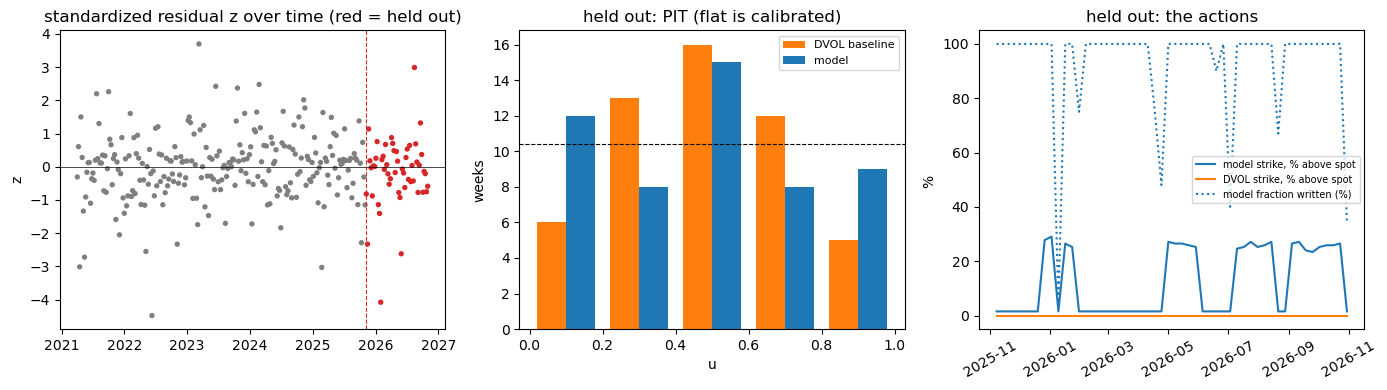

In [16]:
u_model = (R_model <= test.r.values[:, None]).mean(axis=1)
u_base = (R_base <= test.r.values[:, None]).mean(axis=1)
z_all = ((pd.concat([train, test]).r - theta[0]) / sigma_of(theta, pd.concat([train, test]), X_RV)).values
t_all = pd.concat([train, test]).t0

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].scatter(t_all, z_all, s=8, c=np.where(t_all >= CUTOFF, "tab:red", "tab:gray"))
ax[0].axhline(0, color="black", lw=0.5)
ax[0].axvline(CUTOFF, color="tab:red", ls="--", lw=0.8)
ax[0].set(title="standardized residual z over time (red = held out)", ylabel="z")
bins = np.linspace(0, 1, 6)
ax[1].hist([u_base, u_model], bins=bins, color=["tab:orange", "tab:blue"], label=["DVOL baseline", "model"])
ax[1].axhline(N / 5, color="black", ls="--", lw=0.8)
ax[1].set(title="held out: PIT (flat is calibrated)", xlabel="u", ylabel="weeks")
ax[1].legend(fontsize=8)
ax[2].plot(test.t0, 100 * (np.exp(pl_model.q) - 1), color="tab:blue", label="model strike, % above spot")
ax[2].plot(test.t0, 100 * (np.exp(pl_base.q) - 1), color="tab:orange", label="DVOL strike, % above spot")
ax[2].plot(test.t0, 100 * pl_model.f, color="tab:blue", ls=":", label="model fraction written (%)")
ax[2].set(title="held out: the actions", ylabel="% ")
ax[2].legend(fontsize=7)
ax[2].tick_params(axis="x", rotation=30)
fig.tight_layout()
fig.savefig(FIG / "residuals_covered_call.png", dpi=150)
plt.show()

In [17]:
taus = [0.1, 0.25, 0.5, 0.75, 0.9]
cal = pd.DataFrame({"model": [np.mean(u_model <= t) for t in taus], "DVOL baseline": [np.mean(u_base <= t) for t in taus]},
                   index=[f"share of weeks with u <= {t}" for t in taus])
cal.loc["share of weeks with u > 0.9 (upper tail)"] = [np.mean(u_model > 0.9), np.mean(u_base > 0.9)]
display(cal.round(3))
print("expected 10% in the upper tail is", round(0.1 * N, 1), "of", N, "weeks; model:", int((u_model > 0.9).sum()),
      "baseline:", int((u_base > 0.9).sum()),
      "; binomial p-values", round(binomtest(int((u_model > 0.9).sum()), N, 0.1).pvalue, 3),
      round(binomtest(int((u_base > 0.9).sum()), N, 0.1).pvalue, 3))
half = N // 2
print("mean |PIT - 0.5|, first vs second half of held-out: model",
      round(np.abs(u_model[:half] - 0.5).mean(), 3), round(np.abs(u_model[half:] - 0.5).mean(), 3),
      "; baseline", round(np.abs(u_base[:half] - 0.5).mean(), 3), round(np.abs(u_base[half:] - 0.5).mean(), 3), "(uniform: 0.25)")
print("mean growth per week, first vs second half of held-out: model Kelly",
      round(lg["Model, Kelly fraction"][:half].mean(), 5), round(lg["Model, Kelly fraction"][half:].mean(), 5))

,model,DVOL baseline
share of weeks with u <= 0.1,0.096,0.077
share of weeks with u <= 0.25,0.269,0.231
share of weeks with u <= 0.5,0.615,0.500
share of weeks with u <= 0.75,0.769,0.846
share of weeks with u <= 0.9,0.962,0.962
share of weeks with u > 0.9 (upper tail),0.038,0.038


expected 10% in the upper tail is 5.2 of 52 weeks; model: 2 baseline: 2 ; binomial p-values 0.168 0.168
mean |PIT - 0.5|, first vs second half of held-out: model 0.23 0.23 ; baseline 0.204 0.211 (uniform: 0.25)
mean growth per week, first vs second half of held-out: model Kelly 0.00762 0.0029


### Reading the calibration

- **Tails.** Both predictive distributions were exceeded in the upper tail (above the 90th percentile) in 2 of 52 weeks, against about 5 expected (binomial p = 0.17). That is not a detectable miscalibration, but the upper tail was a little thin in the held-out year, which helped call writers. The lower tail is close to nominal (model 9.6 percent below the 10th percentile, baseline 7.7 percent).
- **Noise or bias.** The model's realized returns fell below its median in 61.5 percent of weeks (32 of 52, p = 0.13 against one half), where the baseline's is exactly 50 percent. That is a mild upward bias of the model's median, from the fitted drift of +0.4 percent a week against a held-out mean of -0.6 percent. It is within noise for 52 weeks, but it points the same way as the falling market.
- **Error over the horizon.** The forecast horizon is fixed at one week, so there is no error-versus-horizon curve. From the first half of the held-out weeks to the second, the spread of the PIT is unchanged for the model (0.23 and 0.23) and the baseline (0.204 and 0.211), so neither forecast decayed. The model's Kelly growth was 0.0076 a week in the first half and 0.0029 in the second, which is noisy at 26 weeks each.

## Decision: how the action moves with the inputs

The table holds the model's inputs at their held-out medians and moves DVOL only, then does the same for realized volatility. Each row applies the frozen rule to a hypothetical Friday, with the premium priced at DVOL.

In [18]:
med_d, med_x = test.d.median(), test[X_RV].median()
med_dvol = test.dvol.median()


def what_if(dvols, xs):
    df = pd.DataFrame({"dvol": dvols, "d": np.asarray(dvols) * np.sqrt(T_WEEK), X_RV: np.asarray(xs) * np.sqrt(T_WEEK)})
    sg = sigma_of(theta, df, X_RV).values
    pl = plan(df.dvol.values, theta[0] + sg[:, None] * z[None, :])
    return pd.DataFrame({"strike, % above spot": 100 * (np.exp(pl.q.to_numpy()) - 1), "fraction written": pl.f.to_numpy(),
                         "expected gain, BTC/week": pl.exp_gain.to_numpy()}, index=np.round(dvols if len(set(dvols)) > 1 else xs, 2))


grid = np.array([0.30, 0.35, 0.38, 0.40, 0.42, 0.45, 0.50, 0.60, 0.80])
rv_med = test[X_RV].median() / np.sqrt(T_WEEK)
print(f"DVOL moves, realized vol fixed at its held-out median ({rv_med:.2f}); index = annualized DVOL")
display(what_if(grid, np.full(len(grid), rv_med)).round(4))
print(f"realized vol moves, DVOL fixed at its held-out median ({med_dvol:.2f}); index = annualized realized vol")
display(what_if(np.full(len(grid), med_dvol), grid).round(4))

DVOL moves, realized vol fixed at its held-out median (0.41); index = annualized DVOL


,"strike, % above spot",fraction written,"expected gain, BTC/week"
0.30,20.9250,1.00,0.0000
0.35,23.3678,1.00,0.0000
0.38,24.6077,1.00,0.0000
0.40,1.5113,0.26,0.0002
0.42,1.5113,0.71,0.0007
0.45,1.5113,1.00,0.0014
0.50,1.5113,1.00,0.0027
0.60,1.5113,1.00,0.0055
0.80,2.0201,1.00,0.0116


realized vol moves, DVOL fixed at its held-out median (0.42); index = annualized realized vol


,"strike, % above spot",fraction written,"expected gain, BTC/week"
0.30,28.4025,1.00,0.0000
0.35,1.5113,0.08,0.0001
0.38,1.5113,0.43,0.0004
0.40,1.5113,0.65,0.0007
0.42,1.5113,0.86,0.0009
0.45,1.5113,1.00,0.0011
0.50,1.5113,1.00,0.0016
0.60,1.5113,1.00,0.0023
0.80,1.5113,1.00,0.0034


### Reading the table

- **DVOL.** Below about 0.38 the rule writes far out of the money and the expected gain is zero to four decimals. At 0.40 it switches to a strike about 1.5 percent above spot, at a fraction of 0.26. The fraction rises to 1.0 by 0.45 and the expected gain grows from 0.0002 to 0.0116 BTC a week at 0.80. The model's scale grows only as DVOL to the power 0.63, so it treats high implied volatility as overpriced. That is the assumption that implied volatility stays above realized volatility after the training years, and it is worth testing for the final. Rows above the held-out range (the held-out maximum is 0.83) are extrapolation.
- **Realized volatility.** The fraction rises as realized volatility rises, from 0.08 at 0.35 to 1.0 at 0.45 and above. That is the sign of the fitted $\gamma = -0.21$: more realized volatility lowers the predicted volatility, which makes the premium look richer. Since $\gamma$ is not distinguishable from zero, this direction should not be trusted.

## If the premium is wrong

The premium is the assumption I trust least: Black-Scholes at DVOL, with no spread, skew or fee. Suppose the market pays only $(1 - h)$ of that price, for a haircut $h$ from 0 to 50 percent. Two cases are scored on the held-out year. In the first, the rule is the one already set (same strikes and fractions) and only the premium collected is lower, which is what happens if the assumption is wrong and nobody knows it. In the second, the rule is set again with the lower premium, so the action moves. The DVOL baseline is scored the first way, next to the model.

In [19]:
HAIRCUTS = [0, 0.05, 0.10, 0.20, 0.30, 0.50]


def real_growth(pl, h):
    """Growth when the rule in `pl` was set with no haircut but the market pays (1 - h) of the premium."""
    gain = (1 - h) * pl.prem.values - np.maximum(0, 1 - np.exp(pl.q.values - test.r.values))
    return np.log1p(pl.f.values * gain)


_premium = premium            # plan() reads the global `premium`, so it is swapped for each row and restored
rows = {}
for h in HAIRCUTS:
    premium = lambda dvol, h=h: (1 - h) * _premium(dvol)
    redo = plan(test.dvol.values, R_model)              # a rule that knows the premium is lower
    g_frozen, g_base = real_growth(pl_model, h), real_growth(pl_base, h)
    rows[f"{h:.0%}"] = {"model, rule as set": g_frozen.mean(), "worst week": g_frozen.min(),
                        "DVOL baseline, rule as set": g_base.mean(),
                        "model, rule re-set": growth(test, redo, redo.f.values)[0].mean(),
                        "re-set: mean strike, % above spot": 100 * (np.exp(redo.q) - 1).mean(), "re-set: mean fraction": redo.f.mean()}
premium = _premium
haircut = pd.DataFrame(rows).T.rename_axis("premium haircut")
display(haircut.round(5))
slope = np.polyfit(HAIRCUTS, haircut["model, rule as set"].values, 1)
print(f"model, rule as set: growth falls {-slope[0] / 10:.5f} a week per 10% haircut and reaches zero at a {-slope[1] / slope[0]:.0%} haircut")

,"model, rule as set",worst week,"DVOL baseline, rule as set","model, rule re-set","re-set: mean strike, % above spot",re-set: mean fraction
premium haircut,,,,,,
0%,0.00526,-0.04011,0.00483,0.00526,12.36833,0.92962
5%,0.00476,-0.04133,0.00392,0.00438,15.82949,0.96346
10%,0.00427,-0.04256,0.00301,0.00337,17.34691,0.96385
20%,0.00327,-0.04501,0.00119,0.00047,23.88188,0.97942
30%,0.00228,-0.04746,-0.00064,0.00055,25.37555,0.98596
50%,0.00028,-0.05239,-0.00431,0.00011,26.58346,1.00000


model, rule as set: growth falls 0.00100 a week per 10% haircut and reaches zero at a 53% haircut


### Reading the premium check

Numbers below are from the run saved with this notebook, in log BTC per coin per week against holding.

- **The rule as set loses about 0.0010 a week per 10 percent of premium, and reaches zero at roughly a 53 percent haircut.** Growth is 0.0053 with no haircut, 0.0043 at 10 percent, 0.0033 at 20 percent and 0.0003 at 50 percent. The worst week barely moves (-4.0 percent, then -4.5 percent at 20 percent), because the strikes do not change. So the gain over holding survives a premium well below the Black-Scholes price.
- **The DVOL baseline is hurt more.** It writes at the money, where the premium is largest, so a proportional haircut costs it more: 0.0048, then 0.0012 at 20 percent and -0.0006 at 30 percent. The model's lead over the baseline grows from +0.0004 with no haircut to +0.0021 at 20 percent. That lead comes from where the strikes sit, not from realized volatility.
- **A rule that knows about the haircut moves out and earns less.** At a 10 percent haircut the mean strike goes from 12 to 17 percent above spot and the fraction from 0.93 to 0.96. At 20 percent the strike is 24 percent above spot and growth is 0.0005, below the 0.0033 of the rule as set. With the lower premium, the model's own distribution (a drift of +0.4 percent a week) prices near-the-money calls as marginal, and the held-out year (mean -0.6 percent a week) paid them. Setting the rule again is the cautious choice if the model is right, and here it cost growth.
- **A limit of this check.** A proportional haircut understates the cost on cheap, far-out-of-the-money calls, where a fixed tick or spread in BTC is a larger share of the premium. The 53 percent figure is therefore optimistic for the far-out weeks, though the notes above find little edge or stake in them.

## What a better forecast is worth

The scale of the question is the held-out growth per week, in log BTC per coin, from the table of scores. Two oracles mark how far a better forecast could go. Neither is a forecast anyone could make, and both are scored on the same 52 Fridays with the same premiums.

- **Knows the return.** Each week the oracle picks the best strike on the grid with the realized return in hand, and writes a full call. This is the ceiling for any forecast of the return.
- **Knows next week's volatility.** The same location-scale model and the same Kelly rule, but the scale input is the realized volatility of the week being forecast (the root of the sum of squared hourly returns from $t_0$ to $T$), with DVOL in the second slot. It is fit on the training windows alone. This is what a perfect volatility forecast would add to the model, which is the thing the project tries to improve.

In [20]:
# Oracle 1: knows the return. For each week, the best strike on the grid and the full call or nothing.
g_all = premium(test.dvol.values) - np.maximum(0, 1 - np.exp(Q[None, :] - test.r.values[:, None]))
lg["Oracle: knows the return"] = np.log1p(np.maximum(g_all.max(axis=1), 0))

# Oracle 2: knows next week's realized volatility, not its direction. The same model as above, with the
# realized volatility of the week being forecast (hourly returns from t0 to T) in place of DVOL's reading,
# and DVOL in the second slot. Fit on the training windows, residuals resampled as before.
def week_rv(df):
    return np.array([np.sqrt(lr2.loc[a + pd.Timedelta(hours=1):b].sum()) for a, b in zip(df.t0, df["T"])])

tr_o, te_o = train.copy(), test.copy()
tr_o["d"], tr_o["dv"] = week_rv(train), train.d
te_o["d"], te_o["dv"] = week_rv(test), test.d
th_o = fit_scale(tr_o, "dv")
z_o = ((tr_o.r - th_o[0]) / sigma_of(th_o, tr_o, "dv")).values
R_o = th_o[0] + sigma_of(th_o, te_o, "dv").values[:, None] * z_o[None, :]
pl_o = plan(test.dvol.values, R_o)
lg["Oracle: knows next week's volatility"] = growth(test, pl_o, pl_o.f.values)[0]
print(f"volatility-oracle fit: mu {th_o[0]:+.4f}, alpha {th_o[1]:+.2f}, beta on realized {th_o[2]:+.2f}, gamma on DVOL {th_o[3]:+.2f}")

order = ["Hold (do not sell)", "DVOL baseline, Kelly fraction", "Model, Kelly fraction",
         "Oracle: knows next week's volatility", "Oracle: knows the return"]
value = pd.DataFrame({
    "growth per week": [lg[k].mean() for k in order],
    "SE": [lg[k].std(ddof=1) / np.sqrt(N) for k in order],
    "total, 52 weeks": [lg[k].sum() for k in order],
    "worst week": [lg[k].min() for k in order]}, index=order)
display(value.round(5))
steps = [("Model over DVOL baseline", "Model, Kelly fraction", "DVOL baseline, Kelly fraction"),
         ("Volatility oracle over model", "Oracle: knows next week's volatility", "Model, Kelly fraction"),
         ("Return oracle over volatility oracle", "Oracle: knows the return", "Oracle: knows next week's volatility")]
rows = {}
for label, a, b in steps:
    dlt = lg[a] - lg[b]
    rows[label] = {"growth per week": dlt.mean(), "paired SE": dlt.std(ddof=1) / np.sqrt(N)}
display(pd.DataFrame(rows).T.round(5))

volatility-oracle fit: mu +0.0046, alpha -1.10, beta on realized +1.42, gamma on DVOL -0.86


,growth per week,SE,"total, 52 weeks",worst week
Hold (do not sell),0.00000,0.00000,0.00000,0.00000
"DVOL baseline, Kelly fraction",0.00483,0.00337,0.25129,-0.12522
"Model, Kelly fraction",0.00526,0.00183,0.27350,-0.04011
Oracle: knows next week's volatility,0.00537,0.00146,0.27908,-0.02426
Oracle: knows the return,0.01831,0.00110,0.95204,0.00000


,growth per week,paired SE
Model over DVOL baseline,0.00043,0.00294
Volatility oracle over model,0.00011,0.00167
Return oracle over volatility oracle,0.01294,0.00127


### Reading the value of a better forecast

Numbers below are from the run saved with this notebook, in log BTC per coin per week.

- **Model over the DVOL baseline: +0.0004 a week (paired SE 0.0029).** Over 52 weeks that is 0.02 against a standard error of 0.15, which is noise. What the model buys is smaller swings at similar growth: the worst week is -4.0 percent against -12.5 percent.
- **Knowing next week's volatility exactly adds +0.0001 (SE 0.0017).** Growth does not move, and the worst week improves from -4.0 to -2.4 percent. A better volatility forecast, which is what the project's hypothesis is about, is worth little in growth here. The call's gain depends on whether the price finishes above the strike, and that is a question about direction. (The oracle's two coefficients, 1.42 on realized and -0.86 on DVOL, are not individually meaningful, since the two inputs have a correlation of 0.65.)
- **Knowing the return adds +0.0129 more (SE 0.0013).** The ceiling is 0.0183 a week, 0.95 over the 52 weeks, and almost all of the distance between the model and the ceiling is direction.
- **So** the value of being less wrong about volatility is mostly a lower worst week, not growth, and the value of being less wrong about direction is large but out of reach.

## Implied versus realized volatility

The model's rule writes near the money when DVOL is high, which it can only do if the premium is rich: if implied volatility tends to be above what arrives. The coefficient $\beta = 0.63 < 1$ builds that in. This check asks whether it held, on the training weeks and on the held-out year. For each Friday, the implied volatility is DVOL's previous-day close and the realized volatility is that week's own, both on the weekly scale. The log ratio is negative when the market charged for more volatility than came. Weeks do not overlap, but DVOL is persistent, so the standard errors treat weeks as independent and are probably a little too small.

In [21]:
w["rv_fwd"] = week_rv(w)            # realized volatility of the week being forecast, weekly scale
w["lratio"] = np.log(w.rv_fwd / w.d)  # negative: the market priced more volatility than arrived
sets = {"train": w.iloc[:-N_HOLD], "held out": w.iloc[-N_HOLD:]}
rows = {}
for name, df in sets.items():
    slope, icpt = np.polyfit(np.log(df.d), np.log(df.rv_fwd), 1)
    rows[name] = {"weeks": len(df), "mean implied (DVOL, weekly)": df.d.mean(), "mean realized, that week": df.rv_fwd.mean(),
                  "mean log(realized / implied)": df.lratio.mean(), "SE": df.lratio.std(ddof=1) / np.sqrt(len(df)),
                  "weeks realized < implied": np.mean(df.lratio < 0), "slope of log realized on log implied": slope}
display(pd.DataFrame(rows).T.round(3))

,weeks,"mean implied (DVOL, weekly)","mean realized, that week",mean log(realized / implied),SE,weeks realized < implied,slope of log realized on log implied
train,240.0,0.087,0.073,-0.214,0.019,0.808,0.893
held out,52.0,0.061,0.057,-0.080,0.033,0.750,0.922


### Reading implied versus realized

- **Implied was above realized in most weeks.** In 81 percent of training weeks and 75 percent of held-out weeks, with a mean log ratio of -0.21 (SE 0.02) and -0.08 (SE 0.03). The assumption the rule leans on held in the held-out year.
- **The gap was much thinner in the held-out year.** The mean log ratio moved by 0.13 (about 3.5 standard errors), so the premium collected was closer to fair than in the years the model was fit on. If the gap closes or reverses, the premium stops being rich, and the model's edge over holding goes with it.
- **Implied is informative.** The slope of log realized on log implied is 0.89 in training and 0.92 held out, so realized volatility moves almost one for one with DVOL.
- **A limit of the comparison.** DVOL is a 30-day measure and the realized volatility is for one 7-day week, so the ratio mixes the variance premium with the term structure.

## Simulation check

Does the fit recover parameters it is given? Draw weekly returns from the model with known parameters, using the training windows' own DVOL and realized volatility as inputs and resampling the 240 standardized residuals for the shape. Refit on each simulated sample, 300 times, and compare the estimates with the values that generated them. Two truths are tried: the fitted values, and the same values with $\gamma = 0$, the case in which realized volatility adds nothing. A separate random stream (`SEED + 1`) is used, so the bootstrap above does not change.

The second table asks whether simulated data look like the real data, on four summaries of the weekly return.

In [22]:
NS = 300
sim_rng = np.random.default_rng(SEED + 1)   # its own stream, so the bootstrap above is unchanged
names = ["mu", "alpha", "beta", "gamma"]
truths = {"fitted values": theta, "gamma = 0": theta * np.array([1, 1, 1, 0])}
tables, shape = {}, {}
for label, th_true in truths.items():
    sig = sigma_of(th_true, train, X_RV).values
    est, stats = np.empty((NS, 4)), np.empty((NS, 4))
    for i in range(NS):
        sim = train.copy()
        sim["r"] = th_true[0] + sig * sim_rng.choice(z, len(train))
        est[i] = fit_scale(sim, X_RV)
        stats[i] = [sim.r.std(), sim.r.skew(), sim.r.quantile(0.05), sim.r.quantile(0.95)]
    tables[label] = pd.DataFrame({"true": th_true, "mean estimate": est.mean(0), "sd of estimates": est.std(0),
                                  "5%": np.percentile(est, 5, 0), "95%": np.percentile(est, 95, 0)}, index=names)
    shape[label] = stats
display(pd.concat(tables, names=["truth", "parameter"]).round(3))

real = [train.r.std(), train.r.skew(), train.r.quantile(0.05), train.r.quantile(0.95)]
st = shape["fitted values"]
display(pd.DataFrame({"real training data": real, "simulated, 5%": np.percentile(st, 5, 0),
                      "simulated, 95%": np.percentile(st, 95, 0)},
                     index=["sd of r", "skew of r", "5th percentile of r", "95th percentile of r"]).round(3))

true  mean estimate  sd of estimates     5%    95%
truth         parameter                                                     
fitted values mu         0.004          0.003            0.005 -0.005  0.011
              alpha     -1.598         -1.636            0.584 -2.568 -0.659
              beta       0.633          0.611            0.370 -0.046  1.194
              gamma     -0.213         -0.204            0.274 -0.602  0.241
gamma = 0     mu         0.004          0.004            0.003 -0.001  0.008
              alpha     -1.598         -1.638            0.603 -2.668 -0.691
              beta       0.633          0.632            0.369  0.039  1.257
              gamma     -0.000         -0.008            0.276 -0.440  0.472

,real training data,"simulated, 5%","simulated, 95%"
sd of r,0.076,0.068,0.085
skew of r,-0.461,-1.035,0.429
5th percentile of r,-0.111,-0.152,-0.089
95th percentile of r,0.115,0.106,0.145


### Reading the simulation check

- **Recovery.** The mean of the 300 estimates is within 0.04 of the truth for all four parameters in both cases, so the fit is not biased in a way that matters here.
- **Spread.** The estimates of $\alpha$, $\beta$ and $\gamma$ are loose: the standard deviation of $\gamma$ is about 0.27 and of $\beta$ about 0.37. A true $\gamma$ of $-0.21$ and a true $\gamma$ of 0 give nearly the same distribution of estimates, so 240 weeks cannot tell them apart. That agrees with the bootstrap interval for $\gamma$ that includes zero. The bootstrap standard errors (0.23 for $\gamma$, 0.30 for $\beta$) are a little narrower than this spread, so read them as a lower bound on the uncertainty.
- **Against the real data.** Each of the four summaries of the real training returns falls inside the range the model produces. The shape comes from the real residuals, so this checks the scale model more than the shape.

## Limits

**Where the result should not be trusted**

- **The premium is a calculation.** Every gain is a Black-Scholes price at the previous day's DVOL, a 30-day implied volatility used for 7-day options, with no skew, no bid-ask spread and no fees. DVOL is also an input to the forecast, so the price and the predictor share a source. Real quotes could move every number in the score table, and this is the assumption I trust least. The settlement price is also the Coinbase hourly open at Friday 08:00 UTC, not Deribit's own delivery price.
- **One year, one regime.** The 52 held-out weeks are a falling market (mean weekly return -0.6 percent), where most written calls expire worthless. A rising year gives up the upside above the strike, and that cost was not tested out of sample. Differences of a few thousandths of growth per week, such as the model against the DVOL baseline (+0.0004, SE 0.0029), cannot be told from noise.
- **The premium was thinner in the held-out year.** Implied volatility exceeded realized volatility by less than in the training years (mean log ratio -0.08 against -0.21). The rule writes near the money when DVOL is high because it treats the premium as rich, so a gap that closes takes the edge with it.
- **Outside the held-out range of DVOL.** The held-out DVOL ran from about 0.34 to 0.83. Below about 0.38 the rule writes more than 20 percent above spot, where there is almost nothing to gain, and rows beyond the range in the what-if table are extrapolation.
- **The realized-volatility term.** $\gamma = -0.21$ with a 90 percent interval of [-0.58, +0.17], and the simulation shows 240 weeks cannot separate it from zero. The project's hypothesis is not supported, and nothing here shows it is false either.

**What was assumed**

- The shape of the standardized residuals $z$ is stable over time and independent of the inputs, estimated from 240 weeks, with skew -0.30 and a 90th percentile of 1.21 against the normal's 1.28.
- Weeks are scored as independent. Returns do not overlap but the inputs do, so the standard errors are probably a little too small, and the bootstrap's are narrower than the spread the simulation produces.
- The Kelly fraction is computed from the model's own distribution, so an overconfident model overbets. Here the fraction is near 1 and sizing changes almost nothing, so the strike carries the result.

**What would change the decision**

- A gap between implied and realized volatility near zero or negative: the premium is no longer rich, and the rule should be re-derived.
- A rising market in which the held-out comparison against holding turns negative: the covered call is then a way to give up gains, and the rule should write less.
- A traded premium well below the Black-Scholes price: the gain per week shrinks by the difference.

**With more time or data**

- Real option quotes (bid and ask at each Friday 08:00 UTC) in place of Black-Scholes at DVOL, and a settlement price from Deribit.
- More than one held-out regime: a walk-forward refit each week across the full history, not one frozen year.
- A model of direction. A perfect forecast of volatility is worth almost nothing in growth here, and a perfect forecast of the return is worth 0.018 a week, so a signal for the sign of the week is where the value is.

## Figures for the talk

The five figures on the slides, drawn from the results above with no new analysis: the price strip for the title slide, the strike chosen against DVOL (Action), cumulative growth against holding (Reason), the weekly outcomes against the worst weeks of two alternatives (Risk), and growth and worst week for the baseline, the model and the two oracles (Value). Every number in a label is read from a variable computed above. Each figure is saved in `fig/` for `presentation.qmd`.

On the Value slide growth is shown in satoshis (100,000,000 per bitcoin) per coin held, so 0.0053 log growth per coin is about 526,000 satoshis. The figures stay log growth, the unit used everywhere above: simple weekly growth averages about 2 percent more (about 536,000 satoshis for the model).

In [23]:
# FIGURES FOR THE TALK: style shared by the five slide figures
# Color follows the entity on every chart: the model is blue, the DVOL-only baseline orange,
# holding gray, a full at-the-money call violet, and the perfect-foresight oracles aqua.
# Red marks a week behind holding and always comes with a text label.
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter, NullLocator

INK, INK2, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
COL = {"model": "#2a78d6", "baseline": "#eb6834", "hold": MUTED, "atm": "#6250d6",
       "oracle": "#1baf7a", "behind": "#d03b3b"}
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "font.size": 13, "text.color": INK, "axes.labelcolor": INK2, "axes.edgecolor": GRID,
    "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False})

In [24]:
fig, ax = plt.subplots(figsize=(12.8, 3.3))
held = p[p.index >= CUTOFF]
ax.plot(p.index, p.values, lw=0.8, color=MUTED)
ax.plot(held.index, held.values, lw=1.3, color=COL["model"])
ax.axvspan(CUTOFF, p.index[-1], color=COL["model"], alpha=0.10, lw=0)
ax.set_yscale("log")
ax.set_ylim(14000, 200000)
ax.set_yticks([20000, 50000, 100000])
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v / 1000:.0f}k"))
ax.yaxis.set_minor_locator(NullLocator())
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_xlim(p.index[0], p.index[-1] + pd.Timedelta(days=10))
mid = CUTOFF + (p.index[-1] - CUTOFF) / 2
ax.text(mid, 185000, "52 test weeks,\nnever used to fit", ha="center", va="top", fontsize=13, color=INK)
ax.set_ylabel("BTC/USD")
fig.tight_layout()
fig.savefig(FIG / "deck_title.png", dpi=200)
plt.close(fig)

In [25]:
fig, ax = plt.subplots(figsize=(8.2, 4.9))
dvol_pct = 100 * test.dvol.values
strike_pct = 100 * (np.exp(pl_model.q.values) - 1)
near = strike_pct < 5
ax.scatter(dvol_pct[~near], strike_pct[~near], s=120, color=MUTED, edgecolor=SURF, linewidth=1.5, zorder=3)
ax.scatter(dvol_pct[near], strike_pct[near], s=120, color=COL["model"], edgecolor=SURF, linewidth=1.5, zorder=3)
ax.set_xlabel("DVOL, the market's expected volatility (annualized %)")
ax.set_ylabel("Strike chosen, % above spot")
ax.set_ylim(-2, 33)
ax.set_xlim(dvol_pct.min() - 3, dvol_pct.max() + 3)
ax.text(47, 5.5, f"Near the money\n{near.sum()} of {len(near)} weeks", ha="left", va="bottom", fontsize=14, color=INK)
ax.text(46, 26.5, f"Far out of the money\n{(~near).sum()} of {len(near)} weeks", ha="left", va="center", fontsize=14, color=INK)
fig.tight_layout()
fig.savefig(FIG / "deck_action.png", dpi=200)
plt.close(fig)

In [26]:
def cum_pct(x):
    return 100 * (np.exp(np.concatenate([[0.0], np.cumsum(x)])) - 1)


dates = [test.t0.iloc[0]] + list(test["T"])
series = [("DVOL only", "baseline", lg["DVOL baseline, Kelly fraction"], 2.2),
          ("Model", "model", lg["Model, Kelly fraction"], 3.4)]
fig, ax = plt.subplots(figsize=(11.6, 4.4))
ax.plot([dates[0], dates[-1]], [0, 0], color=COL["hold"], lw=2.2, zorder=2)
for label, key, x, lw in series:
    y = cum_pct(x)
    ax.plot(dates, y, color=COL[key], lw=lw, solid_capstyle="round", zorder=3)
    ax.scatter(dates[-1], y[-1], s=70, color=COL[key], edgecolor=SURF, linewidth=1.5, zorder=4)
    ax.text(dates[-1] + pd.Timedelta(days=9), y[-1], f"{label} {y[-1]:+.0f}%", va="center", fontsize=14,
            fontweight="bold" if key == "model" else "normal")
ax.text(dates[-1] + pd.Timedelta(days=9), 0, "Holding", va="center", fontsize=14, color=INK2)
ax.set_xlim(dates[0], dates[-1] + pd.Timedelta(days=62))
ax.set_xticks([d for d in pd.date_range(dates[0], dates[-1], freq="MS")][1::2])
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:+.0f}%" if v else "0"))
ax.set_ylabel("More bitcoin than holding")
fig.tight_layout()
fig.savefig(FIG / "deck_reason.png", dpi=200)
plt.close(fig)

In [27]:
weekly = 100 * lg["Model, Kelly fraction"]
behind = weekly < 0
worst_base = 100 * lg["DVOL baseline, Kelly fraction"].min()
worst_atm = 100 * lg["Full call, DVOL strike"].min()
fig, ax = plt.subplots(figsize=(11.6, 4.4))
wk = test.t0.reset_index(drop=True)
ax.bar(wk[~behind], weekly[~behind], width=5, color=COL["model"], label=f"Ahead of, or level with, holding: {(~behind).sum()} weeks")
ax.bar(wk[behind], weekly[behind], width=5, color=COL["behind"], label=f"Behind holding: {behind.sum()} weeks")
ax.axhline(0, color=INK2, lw=1)
left = test.t0.iloc[0] - pd.Timedelta(days=4)
for y, key, text in [(worst_base, "baseline", f"DVOL-only baseline, worst week {worst_base:.1f}%"),
                     (worst_atm, "atm", f"Full at-the-money call, worst week {worst_atm:.1f}%")]:
    ax.plot([left, test["T"].iloc[-1]], [y, y], color=COL[key], lw=2.4, zorder=2)
    ax.text(left + pd.Timedelta(days=3), y + 0.5, text, va="bottom", fontsize=13.5)
# the longest run of weeks with almost nothing at stake (calls written far out of the money)
quiet = np.abs(weekly) < 0.05
best, run_start, best_span = 0, None, None
for j, q_ in enumerate(list(quiet) + [False]):
    if q_ and run_start is None:
        run_start = j
    if not q_ and run_start is not None:
        if j - run_start > best:
            best, best_span = j - run_start, (run_start, j - 1)
        run_start = None
mid_gap = wk.iloc[best_span[0]] + (wk.iloc[best_span[1]] - wk.iloc[best_span[0]]) / 2
ax.text(mid_gap, 1.0, "calls far out of the\nmoney: about 0", ha="center", va="bottom", fontsize=12, color=INK2)
i = weekly.argmin()
ax.text(test.t0.iloc[i] + pd.Timedelta(days=9), weekly[i] - 0.1, f"Model's worst week {weekly[i]:.1f}%", va="center", fontsize=13.5)
ax.set_ylim(worst_atm - 1.6, weekly.max() + 3.2)
ax.set_xlim(left, test["T"].iloc[-1])
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:+.0f}%" if v else "0"))
ax.set_ylabel("Weekly result vs holding")
ax.legend(loc="upper right", ncol=2, fontsize=13, handlelength=1.2)
fig.tight_layout()
fig.savefig(FIG / "deck_risk.png", dpi=200)
plt.close(fig)

In [28]:
order = [("DVOL\nonly", "DVOL baseline, Kelly fraction", COL["baseline"]),
         ("Model", "Model, Kelly fraction", COL["model"]),
         ("Knows\nvolatility", "Oracle: knows next week's volatility", "#8fd6bb"),
         ("Knows\nthe return", "Oracle: knows the return", COL["oracle"])]
names = [o[0] for o in order]
colors = [o[2] for o in order]
SATS = 100_000_000   # satoshis per bitcoin: log growth of 0.0053 per coin is about 530,000 sats per coin
growth_ = SATS * np.array([value.loc[o[1], "growth per week"] for o in order])
se_ = SATS * np.array([value.loc[o[1], "SE"] for o in order])


def sats_label(v, _=None):
    return "0" if v == 0 else f"{v / 1e6:.3g}M" if abs(v) >= 1e6 else f"{v / 1e3:.0f}k"


worst_ = 100 * np.array([value.loc[o[1], "worst week"] for o in order])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.6, 4.5))
a1.bar(names, growth_, color=colors, width=0.66, edgecolor=SURF, linewidth=1.5)
a1.errorbar(names, growth_, yerr=se_, fmt="none", ecolor=INK2, elinewidth=1.4, capsize=5, zorder=4)
for i, (g_, s_) in enumerate(zip(growth_, se_)):
    a1.text(i, g_ + s_ + 60_000, sats_label(g_), ha="center", va="bottom", fontsize=13)
a1.set_ylim(0, growth_.max() + 400_000)
a1.yaxis.set_major_formatter(FuncFormatter(sats_label))
a1.set_ylabel("")
a2.bar(names, worst_, color=colors, width=0.66, edgecolor=SURF, linewidth=1.5)
for i, w_ in enumerate(worst_):
    a2.text(i, w_ - 0.5, f"{w_:.1f}%" if w_ else "0%", ha="center", va="top", fontsize=13)
a2.axhline(0, color=INK2, lw=1)
a2.set_ylim(worst_.min() - 3, 0.5)
a2.xaxis.tick_top()
a2.tick_params(axis="x", length=0)
a2.spines["bottom"].set_visible(False)
a2.spines["top"].set_visible(False)
a2.set_yticks([0, -5, -10, -15])
a2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%" if v else "0"))
fig.tight_layout(rect=(0, 0, 1, 0.9))
for ax_, title in [(a1, "Growth per week (sats per coin held)"), (a2, "Worst week (% of stack)")]:
    fig.text(ax_.get_position().x0, 0.97, title, ha="left", va="top", fontsize=14, fontweight="bold")
fig.savefig(FIG / "deck_value.png", dpi=200)
plt.close(fig)